# Training the model

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [3]:
df=pd.read_csv('Cleaned_dataset.csv')

In [4]:
df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,1,6,2012,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,0
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,0
4,5,6,2012,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,0


In [5]:
##drop month,day and yyear
df.drop(['day','month','year'],axis=1,inplace=True)

In [6]:
df['Classes'].value_counts()

Classes
fire             131
not fire         101
fire               4
fire               2
not fire           2
not fire           1
not fire           1
not fire           1
Name: count, dtype: int64

In [7]:
## Encoding
df['Classes']=np.where(df['Classes'].str.contains("not fire"),0,1)

In [8]:
df.tail()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
238,30,65,14,0.0,85.4,16.0,44.5,4.5,16.9,6.5,1,1
239,28,87,15,4.4,41.1,6.5,8.0,0.1,6.2,0.0,0,1
240,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,0,1
241,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,0,1
242,24,64,15,0.2,67.3,3.8,16.5,1.2,4.8,0.5,0,1


In [9]:
df['Classes'].value_counts()

Classes
1    137
0    106
Name: count, dtype: int64

In [10]:
## Independent And dependent features
X=df.drop('FWI',axis=1)
y=df['FWI']

In [11]:
X.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0,0


In [12]:
y

0      0.5
1      0.4
2      0.1
3      0.0
4      0.5
      ... 
238    6.5
239    0.0
240    0.2
241    0.7
242    0.5
Name: FWI, Length: 243, dtype: float64

In [13]:
#Train Test Split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

In [14]:
X_train.shape,X_test.shape

((182, 11), (61, 11))

<Axes: >

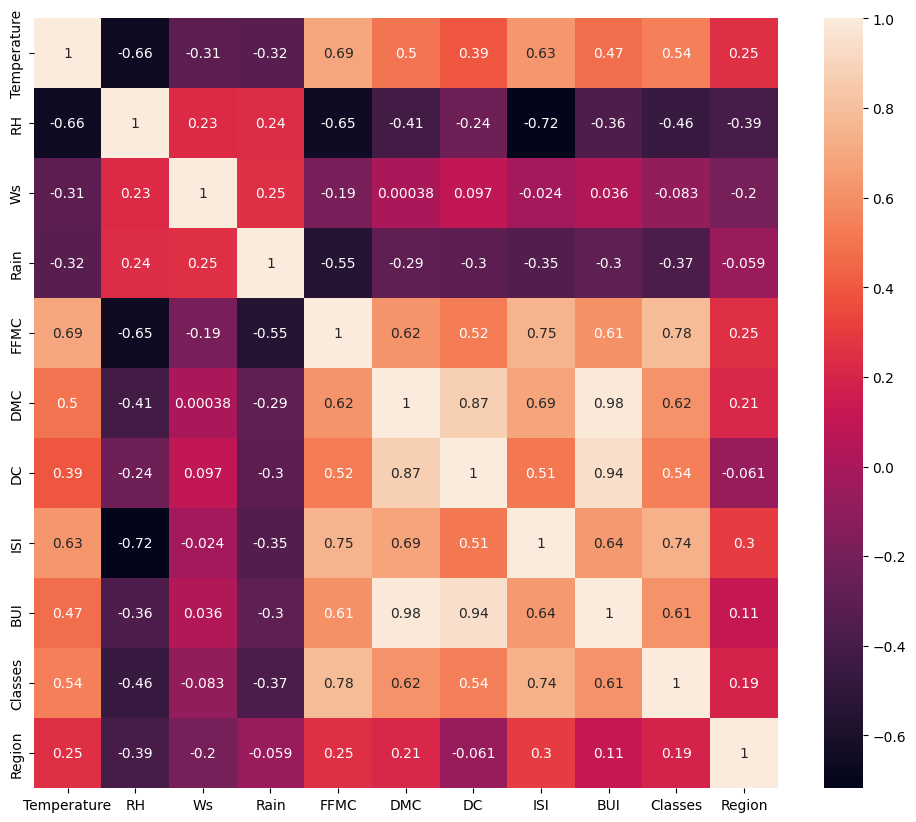

In [15]:
## Check for multicollinearity
plt.figure(figsize=(12,10))
corr=X_train.corr()
sns.heatmap(corr,annot=True)


In [16]:
X_train.corr()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
Temperature,1.000000,-0.656095,-0.305977,-0.317512,0.694768,0.498173,0.390684,0.629848,0.473609,0.542141,0.254549
RH,-0.656095,1.000000,0.225736,0.241656,-0.653023,-0.414601,-0.236078,-0.717804,-0.362317,-0.456876,-0.394665
Ws,-0.305977,0.225736,1.000000,0.251932,-0.190076,0.000379,0.096576,-0.023558,0.035633,-0.082570,-0.199969
Rain,-0.317512,0.241656,0.251932,1.000000,-0.545491,-0.289754,-0.302341,-0.345707,-0.300964,-0.369357,-0.059022
FFMC,0.694768,-0.653023,-0.190076,-0.545491,1.000000,0.620807,0.524101,0.750799,0.607210,0.781259,0.249514
DMC,0.498173,-0.414601,0.000379,-0.289754,0.620807,1.000000,0.868647,0.685656,0.983175,0.617273,0.212582
DC,0.390684,-0.236078,0.096576,-0.302341,0.524101,0.868647,1.000000,0.513701,0.942414,0.543581,-0.060838
ISI,0.629848,-0.717804,-0.023558,-0.345707,0.750799,0.685656,0.513701,1.000000,0.643818,0.742977,0.296441
BUI,0.473609,-0.362317,0.035633,-0.300964,0.607210,0.983175,0.942414,0.643818,1.000000,0.612239,0.114897
Classes,0.542141,-0.456876,-0.082570,-0.369357,0.781259,0.617273,0.543581,0.742977,0.612239,1.000000,0.188837


In [17]:
def correlation(dataset, threshold):
    col_corr = set()
    corr_matrix = dataset.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i, j]) > threshold: 
                colname = corr_matrix.columns[i]
                col_corr.add(colname)
    return col_corr

In [18]:
## threshold--Domain expertise
corr_features=correlation(X_train,0.85)

In [19]:
corr_features

{'BUI', 'DC'}

In [20]:
## drop features when correlation is more than 0.85 
X_train.drop(corr_features,axis=1,inplace=True)
X_test.drop(corr_features,axis=1,inplace=True)
X_train.shape,X_test.shape

((182, 9), (61, 9))

## Scaling and Standardization

In [21]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [22]:
X_train_scaled

array([[-0.84284248,  0.78307967,  1.29972026, ..., -0.62963326,
        -1.10431526, -0.98907071],
       [-0.30175842,  0.64950844, -0.59874754, ..., -0.93058524,
        -1.10431526,  1.01105006],
       [ 2.13311985, -2.08870172, -0.21905398, ...,  2.7271388 ,
         0.90553851,  1.01105006],
       ...,
       [-1.9250106 ,  0.9166509 ,  0.54033314, ..., -1.06948615,
        -1.10431526, -0.98907071],
       [ 0.50986767, -0.21870454,  0.16063958, ...,  0.5973248 ,
         0.90553851,  1.01105006],
       [-0.57230045,  0.98343651,  2.05910739, ..., -0.86113478,
        -1.10431526, -0.98907071]], shape=(182, 9))

### Visualization of the effect of Standard Scalar

Text(0.5, 1.0, 'X_train After Scaling')

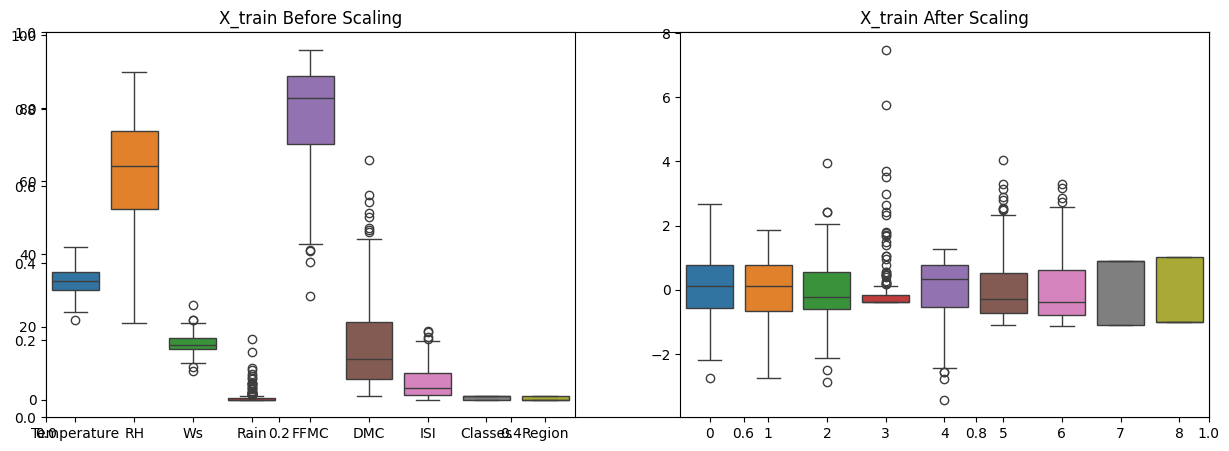

In [23]:
plt.subplots(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.boxplot(data=X_train)
plt.title('X_train Before Scaling')
plt.subplot(1, 2, 2)
sns.boxplot(data=X_train_scaled)
plt.title('X_train After Scaling')

## Model Training

### Linear Regression

Mean absolute error 0.5468236465249978
R2 Score 0.9847657384266951


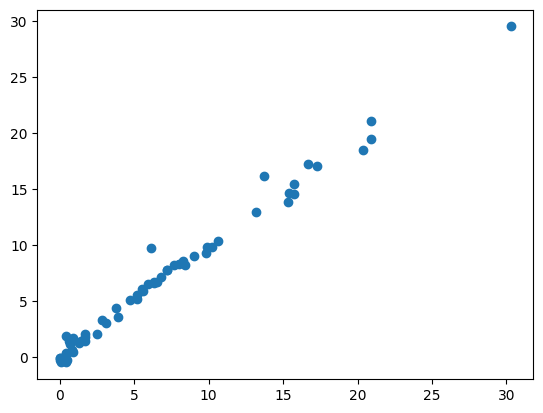

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
linreg=LinearRegression()
linreg.fit(X_train_scaled,y_train)
y_pred=linreg.predict(X_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)
plt.scatter(y_test,y_pred)

### Lasso Regression

Mean absolute error 1.133175994914409
R2 Score 0.9492020263112388


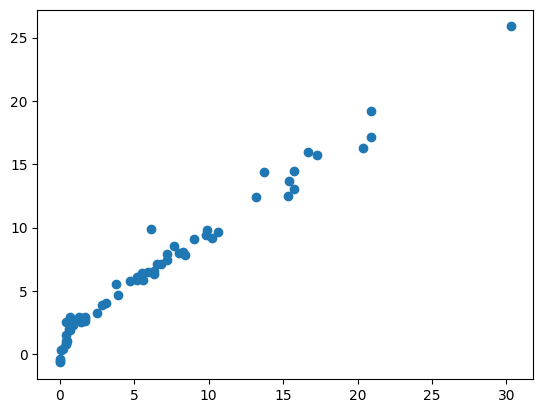

In [25]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
lasso=Lasso()
lasso.fit(X_train_scaled,y_train)
y_pred=lasso.predict(X_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)
plt.scatter(y_test,y_pred)

### Cross Validation Lasso

In [26]:
from sklearn.linear_model import LassoCV
lassocv=LassoCV(cv=5)
lassocv.fit(X_train_scaled,y_train)

,eps,0.001
,n_alphas,'deprecated'
,alphas,'warn'
,fit_intercept,True
,precompute,'auto'
,max_iter,1000
,tol,0.0001
,copy_X,True
,cv,5
,verbose,False
,n_jobs,None


Mean absolute error 0.619970115826343
R2 Score 0.9820946715928275


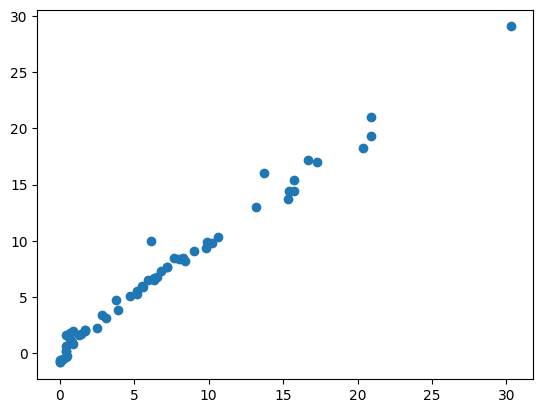

In [27]:
y_pred=lassocv.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)

### Ridge Regression

Mean absolute error 0.5642305340105715
R2 Score 0.9842993364555512


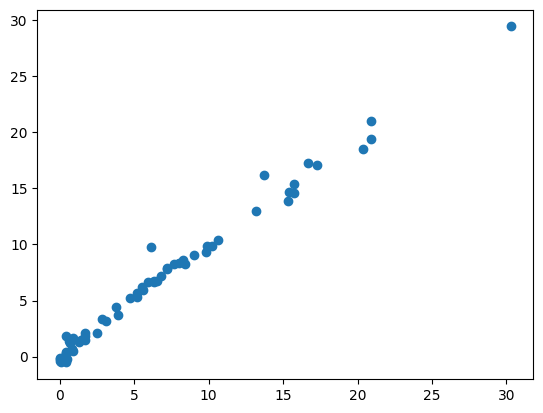

In [28]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
ridge=Ridge()
ridge.fit(X_train_scaled,y_train)
y_pred=ridge.predict(X_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)
plt.scatter(y_test,y_pred)

In [30]:
ridge.get_params()

{'alpha': 1.0,
 'copy_X': True,
 'fit_intercept': True,
 'max_iter': None,
 'positive': False,
 'random_state': None,
 'solver': 'auto',
 'tol': 0.0001}

### Elasticnet Regression

Mean absolute error 1.8822353634896005
R2 Score 0.8753460589519703


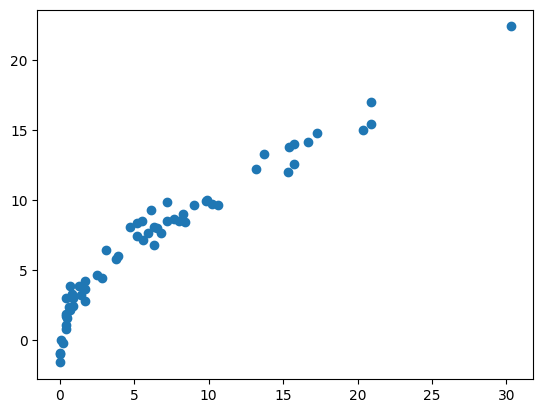

In [31]:
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
elastic=ElasticNet()
elastic.fit(X_train_scaled,y_train)
y_pred=elastic.predict(X_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)
plt.scatter(y_test,y_pred)

Mean absolute error 0.6575946731430898
R2 Score 0.9814217587854941


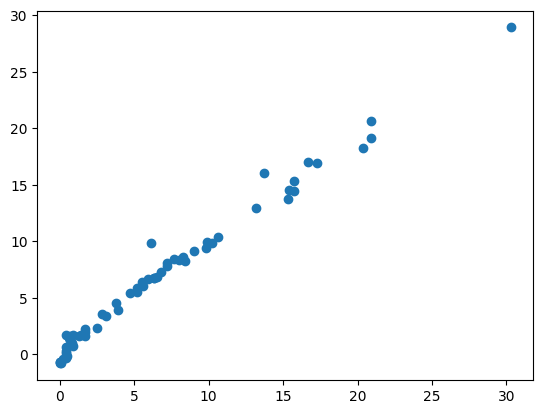

In [32]:
from sklearn.linear_model import ElasticNetCV
elasticcv=ElasticNetCV(cv=5)
elasticcv.fit(X_train_scaled,y_train)
y_pred=elasticcv.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)

# Final conclusion: model comparison and prediction accuracy

The following cells evaluate every trained model on the same held-out test set. MAE, MSE, RMSE, and MAPE should be minimized, while R² should be maximized. MAPE is calculated only for non-zero FWI values because percentage error is undefined for an actual value of zero.

In [33]:
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

models = {
    'Linear Regression': linreg,
    'Lasso': lasso,
    'Lasso CV': lassocv,
    'Ridge': ridge,
    'ElasticNet': elastic,
    'ElasticNet CV': elasticcv,
}

predictions = {name: model.predict(X_test_scaled) for name, model in models.items()}
non_zero_actuals = y_test != 0
metrics = pd.DataFrame([
    {
        'Model': name,
        'MAE': mean_absolute_error(y_test, prediction),
        'MSE': mean_squared_error(y_test, prediction),
        'RMSE': np.sqrt(mean_squared_error(y_test, prediction)),
        'R2': r2_score(y_test, prediction),
        'MAPE (%)': mean_absolute_percentage_error(
            y_test[non_zero_actuals], prediction[non_zero_actuals]
        ) * 100,
    }
    for name, prediction in predictions.items()
]).sort_values('R2', ascending=False).reset_index(drop=True)

display(metrics.style.format({
    'MAE': '{:.3f}',
    'MSE': '{:.3f}',
    'RMSE': '{:.3f}',
    'R2': '{:.3f}',
    'MAPE (%)': '{:.2f}',
}))
best_model_name = metrics.iloc[0]['Model']
print(f"Best overall model by R²: {best_model_name}")

,Model,MAE,MSE,RMSE,R2,MAPE (%)
0,Linear Regression,0.547,0.674,0.821,0.985,41.83
1,Ridge,0.564,0.695,0.834,0.984,42.41
2,Lasso CV,0.620,0.792,0.890,0.982,48.98
3,ElasticNet CV,0.658,0.822,0.907,0.981,48.41
4,Lasso,1.133,2.248,1.499,0.949,66.95
5,ElasticNet,1.882,5.517,2.349,0.875,95.24


Best overall model by R²: Linear Regression


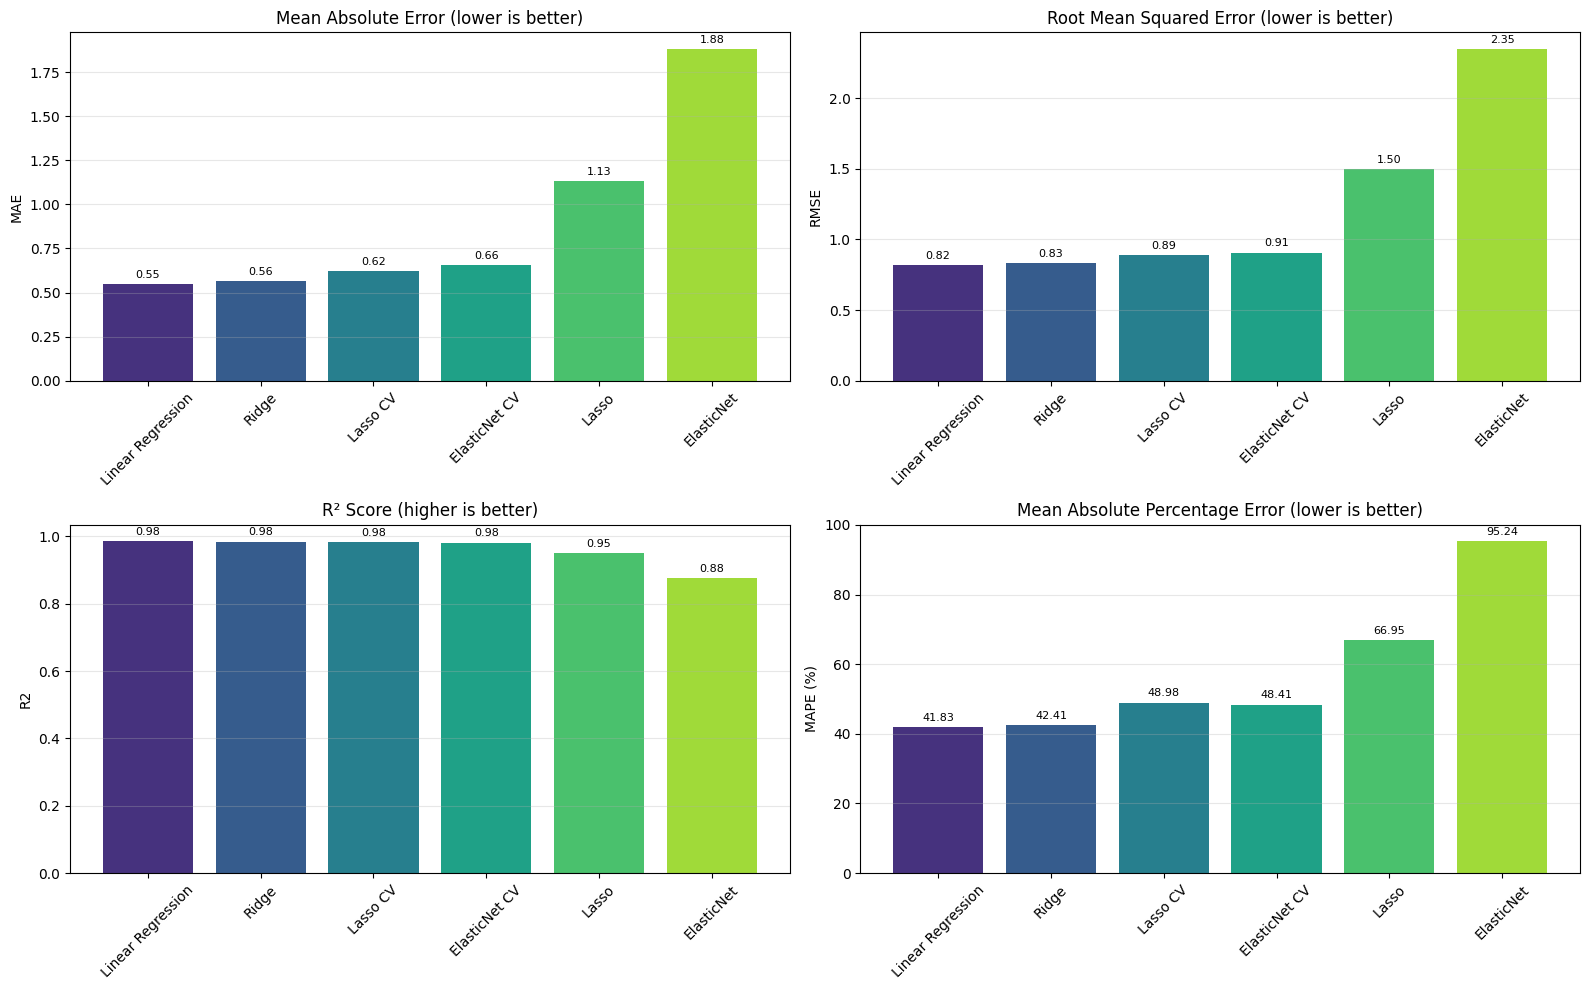

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
metric_axes = [
    ('MAE', 'Mean Absolute Error (lower is better)'),
    ('RMSE', 'Root Mean Squared Error (lower is better)'),
    ('R2', 'R² Score (higher is better)'),
    ('MAPE (%)', 'Mean Absolute Percentage Error (lower is better)'),
]

for axis, (metric, title) in zip(axes.flat, metric_axes):
    bars = axis.bar(metrics['Model'], metrics[metric], color=sns.color_palette('viridis', len(metrics)))
    axis.set_title(title)
    axis.set_ylabel(metric)
    axis.tick_params(axis='x', rotation=45)
    axis.grid(axis='y', alpha=0.3)
    axis.bar_label(bars, fmt='%.2f', padding=3, fontsize=8)

plt.tight_layout()
plt.show()


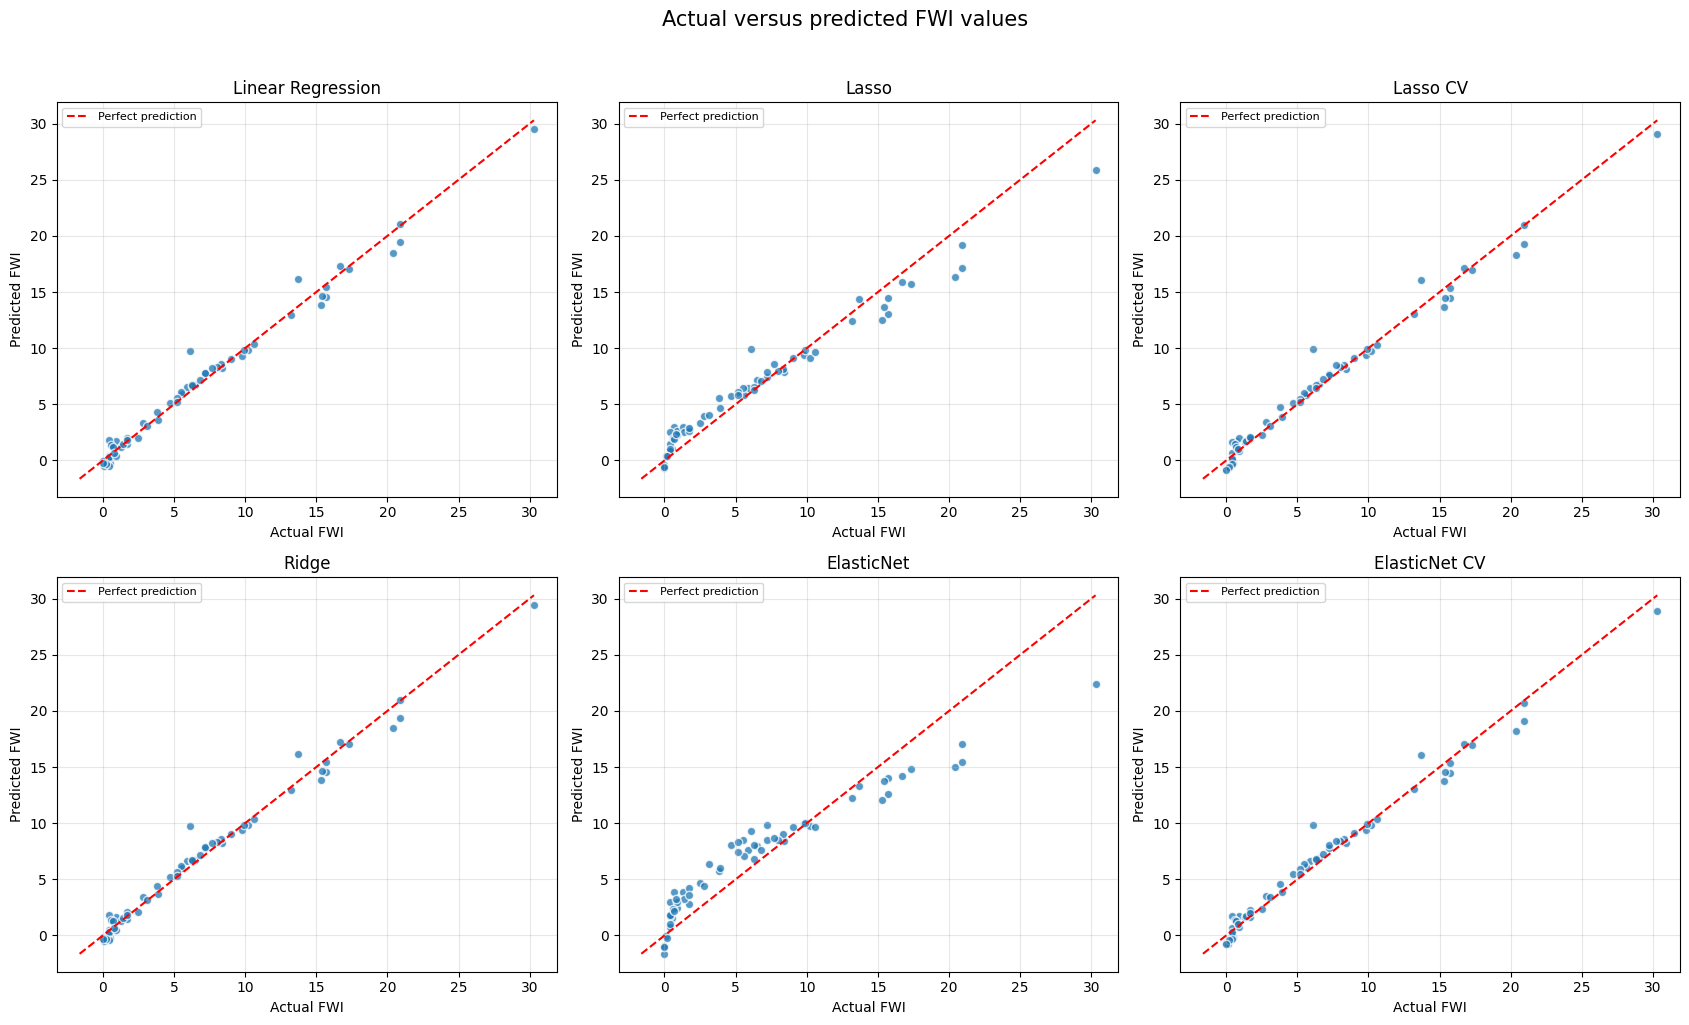

,Actual FWI,Linear Regression prediction,Lasso prediction,Lasso CV prediction,Ridge prediction,ElasticNet prediction,ElasticNet CV prediction,Best model absolute error
0,8.400,8.223,7.846,8.175,8.237,8.440,8.269,0.177
1,7.200,7.753,7.476,7.683,7.771,8.484,7.805,0.553
2,0.500,-0.254,1.063,-0.257,-0.206,1.584,-0.104,0.754
3,3.800,4.356,5.572,4.726,4.386,5.747,4.591,0.556
4,6.500,6.691,7.159,6.787,6.730,7.999,6.887,0.191
5,0.700,1.362,2.985,1.776,1.381,3.845,1.594,0.662
6,2.500,2.039,3.296,2.231,2.098,4.654,2.355,0.461
7,7.200,7.793,7.888,7.641,7.896,9.857,8.062,0.593
8,0.900,1.725,2.649,1.992,1.687,2.412,1.724,0.825
9,2.800,3.332,3.930,3.399,3.396,4.420,3.537,0.532


Linear Regression mean absolute error on the test set: 0.547 FWI points


In [35]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
plot_min = min(y_test.min(), min(prediction.min() for prediction in predictions.values()))
plot_max = max(y_test.max(), max(prediction.max() for prediction in predictions.values()))

for axis, (name, prediction) in zip(axes.flat, predictions.items()):
    axis.scatter(y_test, prediction, alpha=0.75, edgecolor='white')
    axis.plot([plot_min, plot_max], [plot_min, plot_max], 'r--', label='Perfect prediction')
    axis.set_title(name)
    axis.set_xlabel('Actual FWI')
    axis.set_ylabel('Predicted FWI')
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)

plt.suptitle('Actual versus predicted FWI values', y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

prediction_check = pd.DataFrame({'Actual FWI': y_test.to_numpy()})
for name, prediction in predictions.items():
    prediction_check[f'{name} prediction'] = prediction
prediction_check['Best model absolute error'] = np.abs(
    prediction_check['Actual FWI'] - prediction_check[f'{best_model_name} prediction']
)

display(prediction_check.head(10).style.format('{:.3f}'))
print(
    f"{best_model_name} mean absolute error on the test set: "
    f"{metrics.loc[metrics['Model'] == best_model_name, 'MAE'].iloc[0]:.3f} FWI points"
)


Validation completed successfully. Based on the current test split, Linear Regression performs best with:

MAE: 0.547\
MSE: 0.674\
RMSE: 0.821\
R²: 0.985\
MAPE: 41.83%